In [1]:
#THIS NOTEBOOK COMPARES THE SINGLE-TASK BASELINES WITH THE POOLED MULTI-TASK MODEL (Tm + dHfus). THE MODELS WERE TRAINED BY run_baseline.py AND run_multitask.py, THIS NOTEBOOK ONLY READS THE SAVED RESULTS
import pandas as pd                          #IMPORTS THE DATA FRAME HANDLING LIBRARY
import numpy as np                           #IMPORTS THE NUMERICAL LIBRARY
import matplotlib.pyplot as plt              #IMPORTS THE PLOTTING LIBRARY
from scipy import stats                      #IMPORTS THE STATISTICS LIBRARY

def pick_col(df, metric):                    #FINDS THE TEST-SET COLUMN FOR A METRIC ("mae" OR "rmse") IN A BASELINE SEEDS FILE
    options = [c for c in df.columns if "test" in c.lower() and metric in c.lower() and "ring" not in c.lower()]
    assert len(options) >= 1, f"No test {metric} column found in {df.columns.tolist()}"
    return options[0]

In [2]:
mt = pd.read_csv("multitask_seeds_pooled.csv")                  #MULTI-TASK RESULTS, ONE ROW PER (SEED, TASK)
base = {"dHfus": pd.read_csv("baseline_seeds_dHfus.csv"),       #SINGLE-TASK BASELINE RESULTS, ONE ROW PER SEED
        "Tm": pd.read_csv("baseline_seeds_Tm.csv")}

print("Multi-task rows:", len(mt), "| seeds:", [int(s) for s in sorted(mt["seed"].unique())])     #SHOULD BE 20 ROWS AND SEEDS 0-9
print(mt.groupby("task")["n_test"].agg(["min", "max"]))                                           #TEST SET SIZE PER TASK
for task, df_b in base.items():
    print(task, "baseline columns used:", pick_col(df_b, "mae"), "and", pick_col(df_b, "rmse"), "| rows:", len(df_b))

Multi-task rows: 20 | seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
        min   max
task             
Tm     1065  1210
dHfus   234   391
dHfus baseline columns used: test_mae and test_rmse | rows: 10
Tm baseline columns used: test_mae and test_rmse | rows: 10


In [3]:
rows = []
for task in ["Tm", "dHfus"]:
    b = base[task]
    sets = [("Single-task baseline", b[pick_col(b, "mae")].values, b[pick_col(b, "rmse")].values),
            ("Multi-task (pooled)", mt[mt["task"] == task]["mae"].values, mt[mt["task"] == task]["rmse"].values)]
    for model, mae, rmse in sets:
        rows.append(dict(Task=task, Model=model, n_seeds=len(mae),
                         MAE_mean=mae.mean(), MAE_std=mae.std(ddof=1),
                         RMSE_mean=rmse.mean(), RMSE_std=rmse.std(ddof=1),
                         MAE_values=mae, RMSE_values=rmse))                      #KEEPS THE PER-SEED VALUES FOR THE TESTS BELOW

comparison_full = pd.DataFrame(rows)
comparison_df = comparison_full.drop(columns=["MAE_values", "RMSE_values"])
print(comparison_df.round(3).to_string(index=False))
comparison_df.to_csv("multitask_vs_single_comparison.csv", index=False)

 Task                Model  n_seeds  MAE_mean  MAE_std  RMSE_mean  RMSE_std
   Tm Single-task baseline       10    32.665    0.781     42.633     1.115
   Tm  Multi-task (pooled)       10    32.864    0.995     42.715     1.389
dHfus Single-task baseline       10     1.816    0.139      3.359     1.037
dHfus  Multi-task (pooled)       10     1.819    0.296      3.909     1.747


In [4]:
#WELCH T-TEST ON THE PER-SEED SCORES. UNPAIRED, BECAUSE THE TWO MODELS ARE TESTED ON DIFFERENT TEST SETS (THE POOLED SPLIT IS NOT THE SINGLE-TASK SPLIT)
for task in ["Tm", "dHfus"]:
    s = comparison_full[(comparison_full["Task"] == task) & (comparison_full["Model"] == "Single-task baseline")].iloc[0]
    m = comparison_full[(comparison_full["Task"] == task) & (comparison_full["Model"] == "Multi-task (pooled)")].iloc[0]
    for metric in ["MAE", "RMSE"]:
        t_stat, p_val = stats.ttest_ind(m[f"{metric}_values"], s[f"{metric}_values"], equal_var=False)
        diff = m[f"{metric}_mean"] - s[f"{metric}_mean"]
        pct = diff / s[f"{metric}_mean"] * 100
        print(f"{task} {metric}: multi-task minus single-task = {diff:+.3f} ({pct:+.1f}%), Welch p = {p_val:.3f}")

Tm MAE: multi-task minus single-task = +0.199 (+0.6%), Welch p = 0.625
Tm RMSE: multi-task minus single-task = +0.082 (+0.2%), Welch p = 0.886
dHfus MAE: multi-task minus single-task = +0.003 (+0.2%), Welch p = 0.978
dHfus RMSE: multi-task minus single-task = +0.549 (+16.3%), Welch p = 0.407


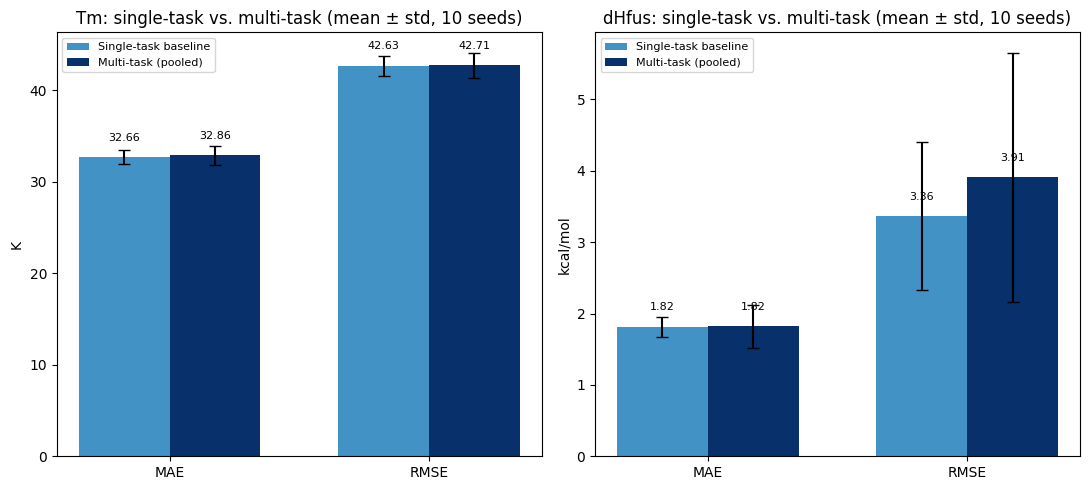

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
colors = {"Single-task baseline": "#4292c6", "Multi-task (pooled)": "#08306b"}
for ax, task in zip(axes, ["Tm", "dHfus"]):
    sub = comparison_df[comparison_df["Task"] == task]
    x = np.arange(2)                                                     #TWO GROUPS: MAE AND RMSE
    width = 0.35
    for i, (_, r) in enumerate(sub.iterrows()):
        vals = [r["MAE_mean"], r["RMSE_mean"]]
        errs = [r["MAE_std"], r["RMSE_std"]]
        bars = ax.bar(x + (i - 0.5) * width, vals, width, yerr=errs, capsize=4, color=colors[r["Model"]], label=r["Model"])
        for bar, v in zip(bars, vals):
            ax.annotate(f"{v:.2f}", xy=(bar.get_x() + bar.get_width() / 2, v), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(["MAE", "RMSE"])
    ax.set_ylabel("K" if task == "Tm" else "kcal/mol")
    ax.set_title(f"{task}: single-task vs. multi-task (mean ± std, 10 seeds)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots_multitask_comparison.png", dpi=150)
plt.show()

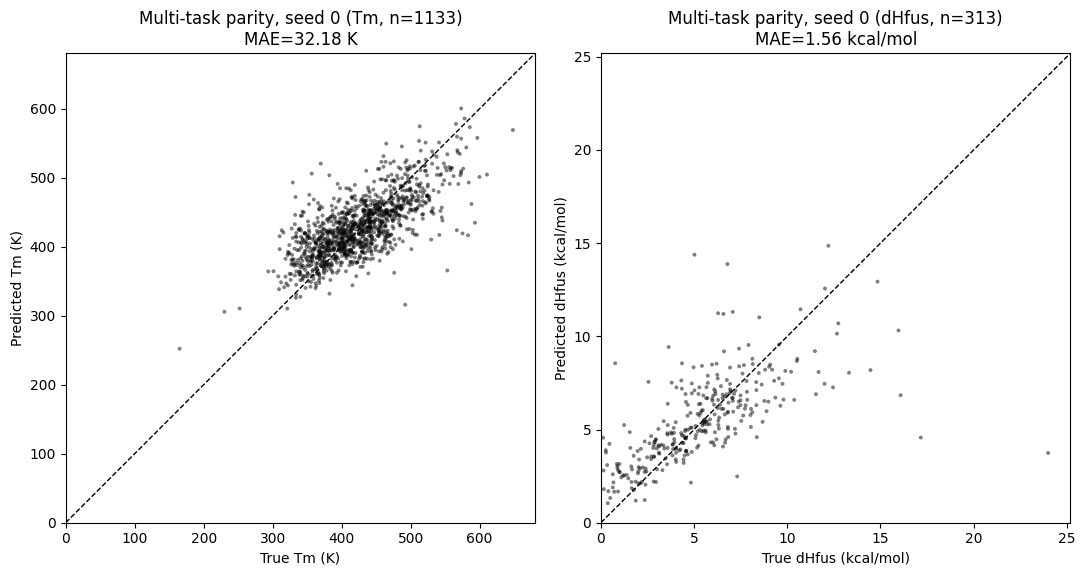

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, task, unit in zip(axes, ["Tm", "dHfus"], ["K", "kcal/mol"]):
    df_p = pd.read_csv(f"multitask_pooled_{task}_predictions.csv").dropna(subset=["y_true"])      #SEED 0 PREDICTIONS
    lim = max(df_p["y_true"].max(), df_p["y_pred"].max()) * 1.05
    ax.scatter(df_p["y_true"], df_p["y_pred"], s=8, alpha=0.5, color="black", edgecolor="none")
    ax.plot([0, lim], [0, lim], "k--", linewidth=1)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"True {task} ({unit})")
    ax.set_ylabel(f"Predicted {task} ({unit})")
    ax.set_title(f"Multi-task parity, seed 0 ({task}, n={len(df_p)})\nMAE={df_p['abs_error'].mean():.2f} {unit}")
plt.tight_layout()
plt.savefig("plots_multitask_parity_seed0.png", dpi=150)
plt.show()


In [1]:
  from chemprop_utils import load_and_pool_multitask_data
  from pathlib import Path
  df_p, _, _ = load_and_pool_multitask_data(Path("RAW DATA")/"dHfus_clean.csv", Path("RAW DATA")/"Tm_clean.csv", "smiles", "dHfus [kcal/mol]", "Tm[K]", tm_sample_size=10000, seed=0)
  print(len(df_p), df_p["dHfus"].notna().sum(), df_p["Tm"].notna().sum(), (df_p["dHfus"].notna() & df_p["Tm"].notna()).sum())

Pooled dataset: 14409 total molecules (4501 with dHfus, 10000 with Tm, 92 with both)


[15:25:59] WARNING: not removing hydrogen atom without neighbors
[15:25:59] WARNING: not removing hydrogen atom without neighbors
[15:25:59] WARNING: not removing hydrogen atom without neighbors
[15:25:59] WARNING: not removing hydrogen atom without neighbors
[15:25:59] WARNING: not removing hydrogen atom without neighbors
[15:26:00] WARNING: not removing hydrogen atom without neighbors
[15:26:00] WARNING: not removing hydrogen atom without neighbors
[15:26:00] Unusual charge on atom 6 number of radical electrons set to zero


After cleaning: 14409 molecules remain


[15:26:01] WARNING: not removing hydrogen atom without neighbors
[15:26:01] WARNING: not removing hydrogen atom without neighbors
[15:26:01] WARNING: not removing hydrogen atom without neighbors
[15:26:01] WARNING: not removing hydrogen atom without neighbors
[15:26:01] WARNING: not removing hydrogen atom without neighbors
[15:26:02] WARNING: not removing hydrogen atom without neighbors
[15:26:02] WARNING: not removing hydrogen atom without neighbors


14409 4501 10000 92


[15:26:02] Unusual charge on atom 6 number of radical electrons set to zero


In [2]:
import pandas as pd
dh = pd.read_csv("RAW DATA/dHfus_clean.csv")["smiles"]
for f in ["RAW DATA/Tm_clean.csv", "RAW DATA/Tm_clean_full.csv"]:
    try:
        tm = pd.read_csv(f)["smiles"]
        print(f, "| ROWS:", len(tm), "| MATCHED WITH dHfus_clean:", dh.isin(tm).sum())
    except FileNotFoundError:
        print(f, "NOT FOUND")

RAW DATA/Tm_clean.csv | ROWS: 10000 | MATCHED WITH dHfus_clean: 92
RAW DATA/Tm_clean_full.csv | ROWS: 269573 | MATCHED WITH dHfus_clean: 2127
